KG Incidenti

In [1]:
import pandas as pd
import ast

from rdflib import Graph, Literal, Namespace, RDF, RDFS
from rdflib.namespace import XSD


# Namespace
EX = Namespace("http://tesi.example.org/ontology/")
NIS2 = Namespace("http://tesi.example.org/nis2/")


def slugify(text: str) -> str:
    if not text or pd.isna(text):
        return "Unknown"

    return (
        "".join(c if c.isalnum() else "_" for c in str(text))
        .strip("_")
    )


def parse_list(value):

    if pd.isna(value):
        return []

    try:
        return ast.literal_eval(value)
    except Exception:
        return [str(value)]


def build_organizations_subgraph(
    df: pd.DataFrame,
    base_graph: Graph = None
) -> Graph:

    g = base_graph if base_graph is not None else Graph()

    g.bind("ex", EX)
    g.bind("nis2", NIS2)
    g.bind("xsd", XSD)

    processed_orgs = set()
    processed_threats = set()

    for _, row in df.iterrows():

        organizzazione = str(row["organizzazione"]).strip()
        regione = str(row["localizzazione"]).strip()
        settore = str(row["settore"]).strip()
        tier = int(row["tier"])

        minacce = parse_list(row["minaccia"])
        sorgenti = parse_list(row["sorgente"])

        company_uri = EX[f"Organization_{slugify(organizzazione)}"]
        sector_uri = EX[f"Sector_{slugify(settore)}"]
        region_uri = EX[f"Region_{slugify(regione)}"]

        # -----------------------
        # ORGANIZZAZIONE
        # -----------------------

        if organizzazione not in processed_orgs:

            processed_orgs.add(organizzazione)

            g.add((company_uri, RDF.type, EX.Organization))

            g.add(
                (
                    company_uri,
                    EX.organizationId,
                    Literal(organizzazione, datatype=XSD.string)
                )
            )

            g.add(
                (
                    company_uri,
                    EX.tier,
                    Literal(tier, datatype=XSD.integer)
                )
            )

            g.add((company_uri, EX.hasAssignedSector, sector_uri))
            g.add((company_uri, EX.locatedInRegion, region_uri))

        # -----------------------
        # SETTORE
        # -----------------------

        g.add((sector_uri, RDF.type, EX.NIS2Sector))

        g.add(
            (
                sector_uri,
                RDFS.label,
                Literal(settore, datatype=XSD.string)
            )
        )

        # -----------------------
        # REGIONE
        # -----------------------

        g.add((region_uri, RDF.type, EX.Region))

        g.add(
            (
                region_uri,
                RDFS.label,
                Literal(regione, datatype=XSD.string)
            )
        )

        # -----------------------
        # MINACCE
        # -----------------------

        for minaccia in minacce:

            threat_uri = EX[f"Threat_{slugify(minaccia)}"]

            if minaccia not in processed_threats:

                processed_threats.add(minaccia)

                g.add((threat_uri, RDF.type, EX.Threat))

                g.add(
                    (
                        threat_uri,
                        RDFS.label,
                        Literal(minaccia, datatype=XSD.string)
                    )
                )

            g.add((company_uri, EX.exposedToThreat, threat_uri))

        # -----------------------
        # SORGENTI
        # -----------------------

        for sorgente in sorgenti:

            source_uri = EX[f"Source_{slugify(sorgente)}"]

            g.add((source_uri, RDF.type, EX.Source))

            g.add(
                (
                    source_uri,
                    RDFS.label,
                    Literal(sorgente, datatype=XSD.string)
                )
            )

            g.add((company_uri, EX.reportedBy, source_uri))

    return g

In [2]:
import pandas as pd
from rdflib import Graph, Literal, Namespace, RDF, RDFS, URIRef
from rdflib.namespace import XSD
import random

import ast


# Definizione dei Namespace
EX = Namespace("http://tesi.example.org/ontology/")
NIS2 = Namespace("http://tesi.example.org/nis2/")


def slugify(text: str) -> str:
  """Normalizza stringhe per creare URI RDF sicuri."""
  if not text or pd.isna(text):
    return "Unknown"
  return (
      "".join(c if c.isalnum() else "_" for c in str(text).strip())
      .strip("_")
      .title()
  )





def build_incidents_subgraph(
    df_incidenti: pd.DataFrame,
    base_graph: Graph = None
) -> Graph:

    g = base_graph if base_graph is not None else Graph()

    g.bind("ex", EX)
    g.bind("nis2", NIS2)
    g.bind("xsd", XSD)

    for _, row in df_incidenti.iterrows():

        # -------------------------------
        # Campi base
        # -------------------------------

        inc_id = (
            str(row.get("id")).strip()
            if pd.notna(row.get("id"))
            else str(random.randint(1, 100000))
        )

        company_name = str(row["denominazione"]).strip()

        dimensione = (
            str(row["dimensione"]).strip().upper()
            if pd.notna(row["dimensione"])
            else "N_D"
        )

        settore = (
            str(row["settore"]).strip()
            if pd.notna(row["settore"])
            else "N_D"
        )

        data_incidente = (
            str(row["data"]).strip()
            if pd.notna(row.get("data"))
            else None
        )

        # -------------------------------
        # URI principali
        # -------------------------------

        incident_uri = EX[f"Incident_{slugify(inc_id)}"]

        company_uri = EX[f"Company_{slugify(company_name)}"]

        sector_uri = EX[f"Sector_{slugify(settore)}"]

        # -------------------------------
        # Azienda
        # -------------------------------

        g.add((company_uri, RDF.type, EX.Company))

        g.add(
            (
                company_uri,
                EX.denominazione,
                Literal(company_name, datatype=XSD.string)
            )
        )

        g.add(
            (
                company_uri,
                EX.dimensioneAziendale,
                EX[f"Dimensione_{dimensione}"]
            )
        )

        g.add(
            (
                company_uri,
                EX.hasAssignedSector,
                sector_uri
            )
        )

        g.add(
            (
                company_uri,
                EX.hasIncident,
                incident_uri
            )
        )

        # -------------------------------
        # Settore
        # -------------------------------

        g.add((sector_uri, RDF.type, EX.Sector))

        g.add(
            (
                sector_uri,
                RDFS.label,
                Literal(settore, datatype=XSD.string)
            )
        )

        # -------------------------------
        # Incidente
        # -------------------------------

        g.add((incident_uri, RDF.type, EX.SecurityIncident))

        g.add(
            (
                incident_uri,
                EX.incidentId,
                Literal(inc_id, datatype=XSD.string)
            )
        )

        g.add(
            (
                incident_uri,
                EX.targetsCompany,
                company_uri
            )
        )

        g.add(
            (
                incident_uri,
                EX.involvesSector,
                sector_uri
            )
        )

        # -------------------------------
        # Data incidente
        # -------------------------------

        if (
            data_incidente
            and data_incidente != "nan"
            and data_incidente != "None"
        ):
            g.add(
                (
                    incident_uri,
                    EX.incidentDate,
                    Literal(
                        data_incidente,
                        datatype=XSD.date
                    )
                )
            )

        # -------------------------------
        # Minacce (NUOVA VERSIONE)
        # -------------------------------

        try:

            minacce = ast.literal_eval(
                str(row["minaccia"])
            )

            if not isinstance(minacce, list):
                minacce = [str(minacce)]

        except Exception:

            minacce = [
                str(row["minaccia"])
            ]

        for minaccia in minacce:

            minaccia = str(minaccia).strip()

            if not minaccia:
                continue

            threat_uri = EX[
                f"Threat_{slugify(minaccia)}"
            ]

            g.add(
                (
                    threat_uri,
                    RDF.type,
                    EX.Threat
                )
            )

            g.add(
                (
                    threat_uri,
                    RDFS.label,
                    Literal(
                        minaccia,
                        datatype=XSD.string
                    )
                )
            )

            g.add(
                (
                    incident_uri,
                    EX.hasThreat,
                    threat_uri
                )
            )

    return g

In [3]:
from pyvis.network import Network


def export_organization_network(
    graph: Graph,
    output_html: str = "organizations_kg.html"
):

    net = Network(
        height="750px",
        width="100%",
        bgcolor="#222222",
        font_color="white"
    )

    net.barnes_hut()

    query = """
    PREFIX ex: <http://tesi.example.org/ontology/>
    PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

    SELECT ?orgId ?regionName ?sectorName ?tier ?threatName ?sourceName
    WHERE {

        ?org a ex:Organization ;
             ex:organizationId ?orgId ;
             ex:tier ?tier ;
             ex:hasAssignedSector ?sector ;
             ex:locatedInRegion ?region .

        ?sector rdfs:label ?sectorName .
        ?region rdfs:label ?regionName .

        OPTIONAL {
            ?org ex:exposedToThreat ?threat .
            ?threat rdfs:label ?threatName .
        }

        OPTIONAL {
            ?org ex:reportedBy ?source .
            ?source rdfs:label ?sourceName .
        }

    }
    """

    added_nodes = set()
    added_edges = set()

    for row in graph.query(query):

        org = str(row.orgId)
        region = str(row.regionName)
        sector = str(row.sectorName)
        tier = str(row.tier)

        threat = (
            str(row.threatName)
            if row.threatName
            else None
        )

        source = (
            str(row.sourceName)
            if row.sourceName
            else None
        )

        # ---------------------------
        # NODI
        # ---------------------------

        if org not in added_nodes:
            net.add_node(
                org,
                label=f"{org}\nTier {tier}",
                color="#97C2FC",
                shape="box"
            )
            added_nodes.add(org)

        if sector not in added_nodes:
            net.add_node(
                sector,
                label=sector,
                color="#7BE141",
                shape="ellipse"
            )
            added_nodes.add(sector)

        if region not in added_nodes:
            net.add_node(
                region,
                label=region,
                color="#FFA500",
                shape="ellipse"
            )
            added_nodes.add(region)

        if threat and threat not in added_nodes:
            net.add_node(
                threat,
                label=threat,
                color="#FB7E81",
                shape="diamond"
            )
            added_nodes.add(threat)

        if source and source not in added_nodes:
            net.add_node(
                source,
                label=source,
                color="#D2B48C",
                shape="dot"
            )
            added_nodes.add(source)

        # ---------------------------
        # ARCHI
        # ---------------------------

        edge = (org, sector, "sector")
        if edge not in added_edges:
            net.add_edge(
                org,
                sector,
                title="belongsToSector"
            )
            added_edges.add(edge)

        edge = (org, region, "region")
        if edge not in added_edges:
            net.add_edge(
                org,
                region,
                title="locatedIn"
            )
            added_edges.add(edge)

        if threat:
            edge = (org, threat, "threat")

            if edge not in added_edges:
                net.add_edge(
                    org,
                    threat,
                    title="exposedToThreat",
                    color="#FB7E81"
                )
                added_edges.add(edge)

        if source:
            edge = (org, source, "source")

            if edge not in added_edges:
                net.add_edge(
                    org,
                    source,
                    title="reportedBy",
                    color="#D2B48C"
                )
                added_edges.add(edge)

    net.show_buttons(filter_=["physics"])

    net.save_graph(output_html)

    print(f"Grafo salvato in: {output_html}")

In [9]:
import pandas as pd
from rdflib import Graph

# Carica il dataset pulito
df_inc = pd.read_csv("temp/incidenti_anonimizzati.csv",sep=";")
df_inc['dimensione']=df_inc['dimensione'].str.replace("Non presente","0")

# Popola il grafo RDF
g = Graph()
build_incidents_subgraph(df_inc, base_graph=g)

# Serializza in formato Turtle per GraphDB o persistenza locale
g.serialize(destination="knowledge_graph_incidenti.ttl", format="turtle")
print(f"Grafo aggiornato con successo: {len(g)} triplette create.")

Grafo aggiornato con successo: 4603 triplette create.


In [10]:
g

<Graph identifier=N9b73b079209045a5a92941f0679abc7c (<class 'rdflib.graph.Graph'>)>

Correlazione dimensione minaccia

In [11]:
query_agg = """
PREFIX ex: <http://tesi.example.org/ontology/>
PREFIX rdfs: <http://www.w3.org/2000/01/rdf-schema#>

SELECT ?settore ?minaccia (COUNT(*) AS ?peso)
WHERE {
  ?incident ex:involvesSector ?sec ;
            ex:hasThreat ?thr .

  ?sec rdfs:label ?settore .
  ?thr rdfs:label ?minaccia .
}
GROUP BY ?settore ?minaccia
ORDER BY DESC(?peso)
"""

In [31]:
results = list(g.query(query_agg))

print("Relazioni aggregate:", len(results))

for r in results[:20]:
    print(r)

Relazioni aggregate: 191
(rdflib.term.Literal("Commercio all'ingrosso e al dettaglio", datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal("['Attacco web-based']", datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal('23', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#integer')))
(rdflib.term.Literal('Altre società private', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal("['Attacco web-based']", datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal('21', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#integer')))
(rdflib.term.Literal('Altre società private', datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal("['Defacement']", datatype=rdflib.term.URIRef('http://www.w3.org/2001/XMLSchema#string')), rdflib.term.Literal('19', datatype=rdflib.term.URIRef('

In [12]:
from pyvis.network import Network

net = Network(
    height="900px",
    width="100%",
    bgcolor="#ffffff",
    font_color="#000000"
)

net.barnes_hut(
    gravity=-5000,
    spring_length=180,
    central_gravity=0.15
)

settori_inseriti = set()
minacce_inserite = set()

for row in g.query(query_agg):

    settore = str(row.settore)

    minaccia = (
        str(row.minaccia)
        .replace("[", "")
        .replace("]", "")
        .replace("'", "")
    )

    peso = int(row.peso)

    # filtro opzionale
    if peso < 3:
        continue

    if settore not in settori_inseriti:

        net.add_node(
            settore,
            label=settore,
            color="#4CAF50",
            shape="dot",
            size=30
        )

        settori_inseriti.add(settore)

    if minaccia not in minacce_inserite:

        net.add_node(
            minaccia,
            label=minaccia,
            color="#F44336",
            shape="diamond",
            size=20
        )

        minacce_inserite.add(minaccia)

    net.add_edge(
        settore,
        minaccia,
        value=peso,
        width=max(1, peso/2),
        title=f"Occorrenze: {peso}"
    )

net.show_buttons(filter_=["physics"])

net.save_graph("matrice_rischio_settore_minaccia.html")

Heatmap

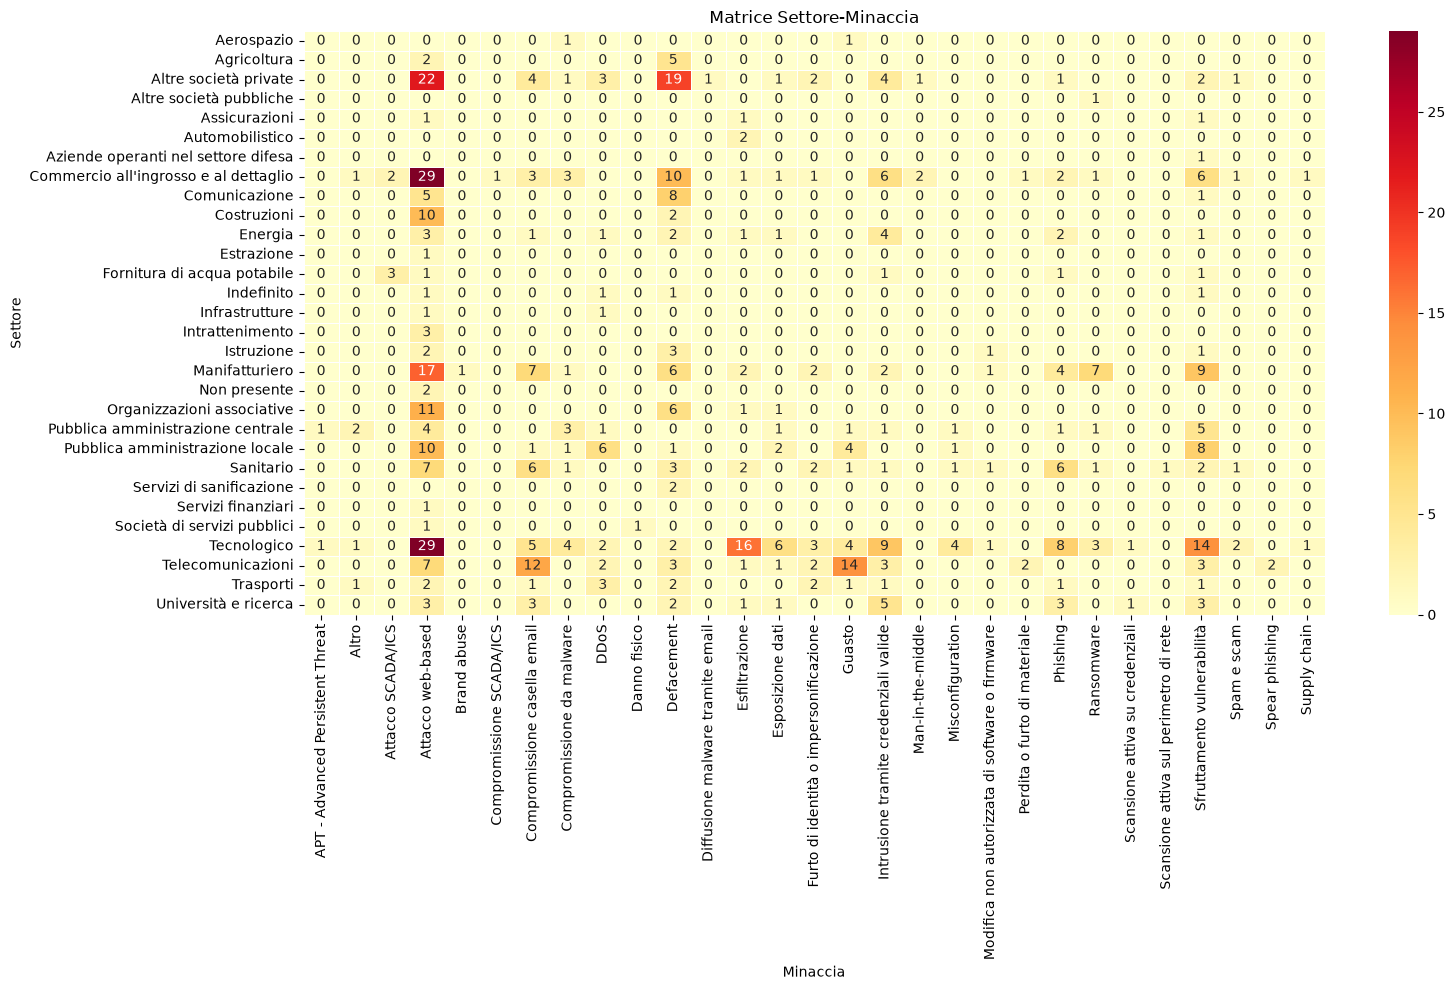

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

rows = []

for row in g.query(query_agg):

    rows.append({
        "settore": str(row.settore),
        "minaccia": str(row.minaccia)
                        .replace("[", "")
                        .replace("]", "")
                        .replace("'", ""),
        "peso": int(row.peso)
    })

df_heat = pd.DataFrame(rows)

pivot = df_heat.pivot_table(
    index="settore",
    columns="minaccia",
    values="peso",
    fill_value=0
)

plt.figure(figsize=(16,10))

sns.heatmap(
    pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.5
)

plt.title("Matrice Settore-Minaccia")
plt.xlabel("Minaccia")
plt.ylabel("Settore")

plt.tight_layout()
plt.show()

In [15]:
import networkx as nx

G = nx.Graph()

for row in g.query(query_agg):

    settore = str(row.settore)

    minaccia = (
        str(row.minaccia)
        .replace("[", "")
        .replace("]", "")
        .replace("'", "")
    )

    peso = int(row.peso)

    G.add_node(
        settore,
        node_type="settore"
    )

    G.add_node(
        minaccia,
        node_type="minaccia"
    )

    G.add_edge(
        settore,
        minaccia,
        weight=peso
    )

print(
    f"Nodi: {G.number_of_nodes()}"
)

print(
    f"Archi: {G.number_of_edges()}"
)

Nodi: 59
Archi: 180


In [16]:
import community.community_louvain as community_louvain
partition = community_louvain.best_partition(
    G,
    weight="weight"
)

num_communities = len(
    set(partition.values())
)

print(
    f"Community individuate: {num_communities}"
)


Community individuate: 6


In [17]:
from collections import defaultdict

communities = defaultdict(list)

for node, community_id in partition.items():
    communities[community_id].append(node)

for cid, nodes in communities.items():

    print("\n")
    print("=" * 50)
    print(f"COMMUNITY {cid}")
    print("=" * 50)

    for n in sorted(nodes):
        print(n)



COMMUNITY 2
APT - Advanced Persistent Threat
Aerospazio
Altro
Assicurazioni
Automobilistico
Aziende operanti nel settore difesa
Compromissione da malware
Energia
Esfiltrazione
Esposizione dati
Intrusione tramite credenziali valide
Misconfiguration
Pubblica amministrazione centrale
Scansione attiva su credenziali
Sfruttamento vulnerabilità
Spam e scam
Supply chain
Tecnologico
Università e ricerca


COMMUNITY 1
Agricoltura
Altre società private
Attacco web-based
Commercio all'ingrosso e al dettaglio
Compromissione SCADA/ICS
Comunicazione
Costruzioni
Defacement
Diffusione malware tramite email
Estrazione
Intrattenimento
Istruzione
Man-in-the-middle
Non presente
Organizzazioni associative
Servizi di sanificazione
Servizi finanziari


COMMUNITY 4
Altre società pubbliche
Brand abuse
Furto di identità o impersonificazione
Manifatturiero
Modifica non autorizzata di software o firmware
Phishing
Ransomware
Sanitario
Scansione attiva sul perimetro di rete


COMMUNITY 5
Compromissione casella em

In [20]:
from pyvis.network import Network
import networkx as nx

net = Network(
    height="900px",
    width="100%",
    bgcolor="#ffffff",
    font_color="#000000"
)

# Palette colori community
palette = [
    "#e41a1c",  # rosso
    "#377eb8",  # blu
    "#4daf4a",  # verde
    "#984ea3",  # viola
    "#ff7f00",  # arancione
    "#a65628",  # marrone
    "#f781bf",  # rosa
    "#999999",  # grigio
]

# Degree centrality per dimensionare i nodi
centrality = nx.degree_centrality(G)

# NODI
for node in G.nodes():

    community_id = partition[node]

    color = palette[
        community_id % len(palette)
    ]

    node_type = G.nodes[node]["node_type"]

    shape = (
        "dot"
        if node_type == "settore"
        else "diamond"
    )

    size = max(
        15,
        min(
            60,
            15 + centrality[node] * 250
        )
    )

    net.add_node(
        node,
        label=node,
        color=color,
        shape=shape,
        size=size,
        title=(
            f"Community: {community_id}<br>"
            f"Tipo: {node_type}<br>"
            f"Centralità: {centrality[node]:.3f}"
        )
    )

# ARCHI
for source, target, data in G.edges(data=True):

    weight = data.get("weight", 1)

    net.add_edge(
        source,
        target,
        value=weight,
        width=max(1, weight / 2),
        title=f"Peso: {weight}",
        color="#666666"
    )

# Layout fisico
net.barnes_hut(
    gravity=-6000,
    central_gravity=0.15,
    spring_length=220,
    spring_strength=0.03
)

net.show_buttons(filter_=["physics"])

net.save_graph("community_detection.html")

print("Creato: community_detection.html")

Creato: community_detection.html
